# Satillite Group 4

### Recognizing the tank

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "pipeline")  # Claas's helpers live in project/pipeline/
import viz

In [2]:
CUSHING = (35.985, -96.767)  # town centre, from config.py, used for the search
CENTRE = (35.967, -96.750)   # 2 km south, 1.5 km east: centre of the window
HALF_KM = 7                  # 14 km square, covers all three farms


We save the image search, every Sentinel 2 window and the OpenStreetMap answer in `data/cache/`, so each file
is downloaded only once. `Satellite_experiments.ipynb` uses the same cache. Windows are named by image id
(for example `S2B_14SQE_20180120_0_L2A.npy`), because one date can have up to four images.

In [3]:
import json
from pathlib import Path

CACHE = Path("data/cache")


def search_items():
    """All Sentinel 2 images over Cushing, 2017 to 2024 (searched once, then read from the cache)."""
    path = CACHE / "s2_items_2017_2024.json"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        found = []
        for year in range(2017, 2025):  # one search per year: a search returns at most 200 images
            found += viz.s2_search(*CUSHING, f"{year}-01-01", f"{year}-12-31")
        path.write_text(json.dumps(found))
    found = json.loads(path.read_text())
    # ten images sit in a paid ("requester pays") bucket with s3:// links: we skip them
    return [item for item in found if item["assets"]["visual"]["href"].startswith("https")]


def load_chip(item):
    """RGB window around CENTRE, downloaded once and then read from the cache."""
    path = CACHE / "s2" / f"{item['id']}.npy"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        chip = viz.s2_chip(item, *CENTRE, half_km=HALF_KM)
        np.save(path, chip)
        props = item["properties"]
        meta = {"id": item["id"], "datetime": props["datetime"], "tile": props["mgrs:grid_square"],
                "processing_baseline": props["s2:processing_baseline"],
                "cloud_cover": props["eo:cloud_cover"], "sun_azimuth": props["view:sun_azimuth"],
                "sun_elevation": props["view:sun_elevation"],
                "no_data": float((chip.sum(axis=2) == 0).mean()),
                "href": item["assets"]["visual"]["href"], "centre": CENTRE, "half_km": HALF_KM}
        path.with_suffix(".json").write_text(json.dumps(meta, indent=1))
    return np.load(path)

In [4]:
items = [item for item in search_items() if item["properties"]["datetime"][:4] == "2018"]
clear = [item for item in items if item["properties"]["eo:cloud_cover"] < 5]
print(f"{len(items)} images in 2018, {len(clear)} almost cloud free")

147 images in 2018, 52 almost cloud free


In [5]:
for item in clear:
    chip = load_chip(item)
    no_data = (chip.sum(axis=2) == 0).mean()  # share of black pixels
    if no_data < 0.01:
        break

reference = item  # the image we draw the tank map on
date = item["properties"]["datetime"][:10]
print(date, f"{no_data:.1%} black pixels")

2018-01-20 0.6% black pixels


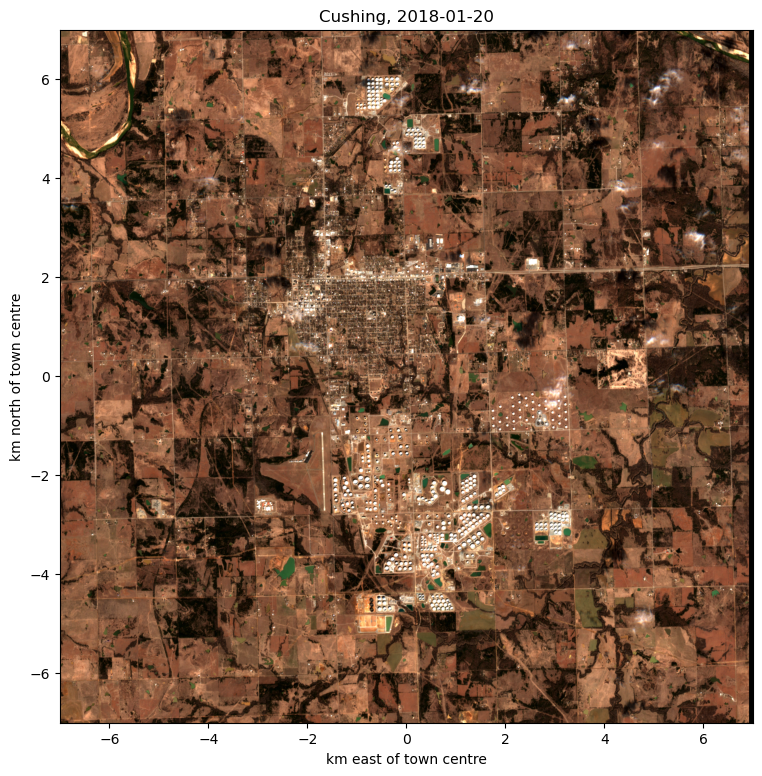

In [6]:
plt.figure(figsize=(9, 9))
plt.imshow(chip, extent=[-HALF_KM, HALF_KM, -HALF_KM, HALF_KM])
plt.title(f"Cushing, {date}")
plt.xlabel("km east of town centre")
plt.ylabel("km north of town centre")
plt.show()

2.1% of pixels are bright


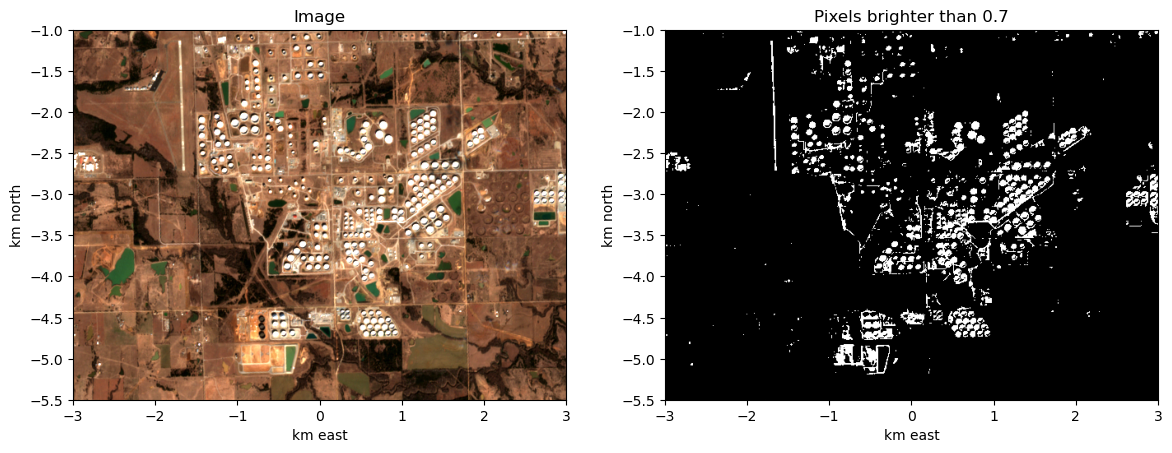

In [7]:
# Check 1

EXTENT = [-HALF_KM, HALF_KM, -HALF_KM, HALF_KM]  # km from the window centre

gray = chip.mean(axis=2) / 255  # brightness: 0 = black, 1 = white
BRIGHT = 0.7                    # first guess, we tune it by eye
mask = gray > BRIGHT            # True where a pixel is brighter than BRIGHT
print(f"{mask.mean():.1%} of pixels are bright")

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(chip, extent=EXTENT)
ax[0].set_title("Image")
ax[1].imshow(mask, cmap="gray", extent=EXTENT)
ax[1].set_title(f"Pixels brighter than {BRIGHT}")
for a in ax:
    a.set_xlim(-3, 3)    # zoom on the big south farm
    a.set_ylim(-5.5, -1)
    a.set_xlabel("km east")
    a.set_ylabel("km north")
plt.show()


Filter 1: 402 round spots
Filter 2: 401 spots with a white centre


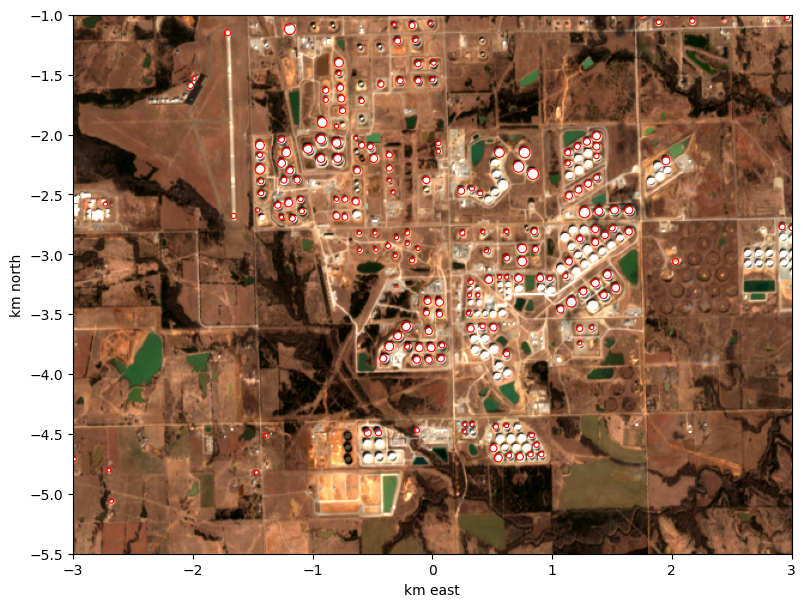

In [8]:
# Check 2

from skimage.feature import blob_log

blobs = blob_log(gray, min_sigma=1.3, max_sigma=3.2, num_sigma=8, threshold=0.3)
print(f"Filter 1: {len(blobs)} round spots")

rows, cols = blobs[:, 0].astype(int), blobs[:, 1].astype(int)
blobs = blobs[gray[rows, cols] > BRIGHT]  # keep spots with a white centre
print(f"Filter 2: {len(blobs)} spots with a white centre")

x_km = blobs[:, 1] * 0.01 - HALF_KM  # column to km east (10 m pixels)
y_km = HALF_KM - blobs[:, 0] * 0.01  # row to km north
r_km = blobs[:, 2] * 1.41 * 0.01     # radius in km

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(chip, extent=EXTENT)
for x, y, r in zip(x_km, y_km, r_km):
    ax.add_patch(plt.Circle((x, y), r, color="red", fill=False, linewidth=0.8))
ax.set_xlim(-3, 3)
ax.set_ylim(-5.5, -1)
ax.set_xlabel("km east")
ax.set_ylabel("km north")
plt.show()

In [9]:
#-----Overpass API------#

import requests

BOX = (35.904, -96.828, 36.030, -96.672)  # south, west, north, east of our 14 km window
query = f"""
[out:json];
nwr["man_made"="storage_tank"]{BOX};
out geom;
"""

HEADERS = {
    "User-Agent": "Bocconi student project (Finance with Big Data), contact: giuliano",
    "Accept": "application/json",
}
URL = "https://overpass-api.de/api/interpreter"

path = CACHE / "osm_tanks.json"
if not path.exists():  # ask OpenStreetMap only once
    answer = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
    answer.raise_for_status()
    path.write_text(answer.text)

tanks = json.loads(path.read_text())["elements"]
print(f"{len(tanks)} objects in OpenStreetMap")
for kind in ("node", "way", "relation"):
    print(kind, sum(t["type"] == kind for t in tanks))

415 objects in OpenStreetMap
node 0
way 415
relation 0


In [10]:
from affine import Affine
from rasterio.transform import rowcol
from rasterio.warp import transform

# Pixel grid of the tile, from the image metadata (no download needed)
grid = Affine(*item["assets"]["visual"]["proj:transform"][:6])
crs = f"EPSG:{item['properties']['proj:epsg']}"
(cx,), (cy,) = transform("EPSG:4326", crs, [CENTRE[1]], [CENTRE[0]])
row0, col0 = rowcol(grid, cx, cy)
half = int(HALF_KM * 1000 / 10)       # 10 m pixels
top, left = row0 - half, col0 - half  # first row and column of our chip
to_image = ~grid                      # satellite map coordinates to (column, row)

centres, radii = [], []
for tank in tanks:
    points = tank["geometry"][:-1]        # the last point repeats the first
    lons = [p["lon"] for p in points]
    lats = [p["lat"] for p in points]
    xs, ys = transform("EPSG:4326", crs, lons, lats)
    cols, rows = zip(*[to_image * (x, y) for x, y in zip(xs, ys)])
    cols, rows = np.array(cols) - left, np.array(rows) - top
    centres.append((rows.mean(), cols.mean()))
    radii.append(np.hypot(rows - rows.mean(), cols - cols.mean()).mean())

centres, radii = np.array(centres), np.array(radii)
print(f"Radius: median {np.median(radii) * 10:.0f} m, "
      f"smallest {radii.min() * 10:.0f} m, largest {radii.max() * 10:.0f} m")

Radius: median 31 m, smallest 9 m, largest 43 m


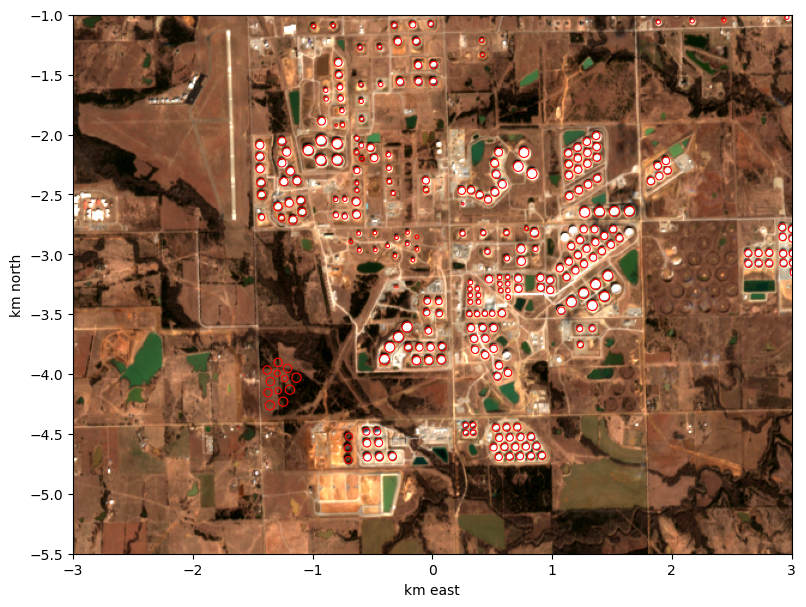

In [11]:
x_km = centres[:, 1] * 0.01 - HALF_KM
y_km = HALF_KM - centres[:, 0] * 0.01

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(chip, extent=EXTENT)
for x, y, r in zip(x_km, y_km, radii * 0.01):
    ax.add_patch(plt.Circle((x, y), r, color="red", fill=False, linewidth=0.8))
ax.set_xlim(-3, 3)
ax.set_ylim(-5.5, -1)
ax.set_xlabel("km east")
ax.set_ylabel("km north")
plt.show()

In [12]:
def tank_brightness(gray, centres, radii):
    """Mean brightness inside each tank circle (0 = black, 1 = white)."""
    values = []
    for (row, col), r in zip(centres, radii):
        r = max(r, 1)  # very small tanks: use at least one pixel
        top, left = int(row - r), int(col - r)
        window = gray[top:int(row + r) + 1, left:int(col + r) + 1]
        rr, cc = np.indices(window.shape)
        inside = np.hypot(rr + top + 0.5 - row, cc + left + 0.5 - col) <= r
        values.append(window[inside].mean())
    return np.array(values)

In [13]:
brightness = []
for item_k in clear[::6]:  # every 6th clear image: about 9 dates
    chip_k = load_chip(item_k)
    brightness.append(tank_brightness(chip_k.mean(axis=2) / 255, centres, radii))
brightness = np.array(brightness)  # one row per date, one column per tank

built = brightness.max(axis=0) > 0.6  # bright on at least one date
print(f"{built.sum()} of {len(built)} tanks existed in 2018")

401 of 415 tanks existed in 2018


In [14]:
if len(centres) == len(built):  # only filter if not done yet
    centres, radii = centres[built], radii[built]
print(len(centres), "tanks kept")

401 tanks kept


### Recognizing the shade

In [15]:
print({k: v for k, v in item["properties"].items() if "sun" in k})

{'view:sun_azimuth': 158.869995494784, 'view:sun_elevation': 31.474956048101802}


L = 25 m = 2.5 pixels, towards 339 degrees


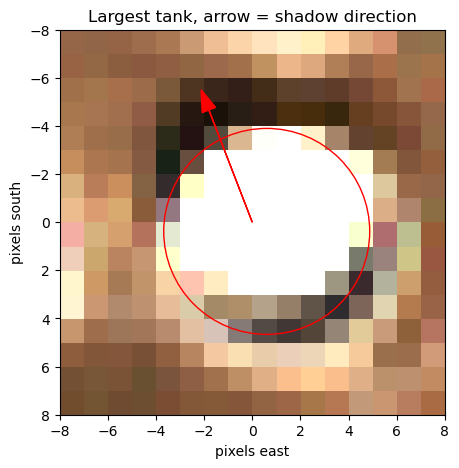

In [16]:
sun_azimuth = item["properties"]["view:sun_azimuth"]
sun_elevation = item["properties"]["view:sun_elevation"]
TANK_HEIGHT = 15  # metres: typical Cushing tanks are 48 ft (14.6 m) high (Oil & Gas Journal; Industrial Info)

L_m = TANK_HEIGHT / np.tan(np.radians(sun_elevation))
shadow_dir = np.radians(sun_azimuth + 180)                # shadows point away from the sun
d_row, d_col = -np.cos(shadow_dir), np.sin(shadow_dir)    # rows grow southward in the image
print(f"L = {L_m:.0f} m = {L_m / 10:.1f} pixels, towards {np.degrees(shadow_dir) % 360:.0f} degrees")

k = np.argmax(radii)  # zoom on the largest tank
row, col = centres[k]
size = 8              # pixels shown on each side of the centre
window = chip[int(row) - size:int(row) + size, int(col) - size:int(col) + size]

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(window, interpolation="nearest", extent=[-size, size, size, -size])
ax.add_patch(plt.Circle((col - int(col), row - int(row)), radii[k], color="red", fill=False))
ax.arrow(0, 0, 5 * d_col, 5 * d_row, color="red", head_width=0.6)
ax.set_title("Largest tank, arrow = shadow direction")
ax.set_xlabel("pixels east")
ax.set_ylabel("pixels south")
plt.show()

In [17]:
DARK = 0.3  # a pixel darker than this counts as shadow (first guess, to check)

def shadow_counts(gray, centres, radii, L_px, d_row, d_col):
    """Dark pixels on the roofs and in the ground shadows, summed over all tanks."""
    roof_dark, ground_dark = 0, 0
    per_tank = []  # dark roof pixels of each tank
    for (row, col), r in zip(centres, radii):
        reach = int(r + L_px) + 2
        top, left = int(row) - reach, int(col) - reach
        window = gray[top:int(row) + reach, left:int(col) + reach]
        rr, cc = np.indices(window.shape)
        y = rr + top + 0.5 - row  # pixel centre, relative to the tank centre
        x = cc + left + 0.5 - col

        on_roof = np.hypot(y, x) <= r
        t = np.clip(y * d_row + x * d_col, 0, L_px)  # how far along the shadow direction
        swept = np.hypot(y - t * d_row, x - t * d_col) <= r
        in_ground_shadow = swept & ~on_roof

        dark = window < DARK
        roof_dark += (dark & on_roof).sum()
        ground_dark += (dark & in_ground_shadow).sum()
        per_tank.append((dark & on_roof).sum())
    return roof_dark, ground_dark, per_tank

In [18]:
for threshold in (0.3, 0.4, 0.5):
    DARK = threshold
    roof_dark, ground_dark, per_tank = shadow_counts(gray, centres, radii, L_m / 10, d_row, d_col)
    print(f"DARK {threshold}: roof {roof_dark}, ground {ground_dark}, ratio {roof_dark / ground_dark:.2f}")

print("Tanks with 0, 1, 2, ... dark roof pixels:", np.bincount(per_tank))

DARK 0.3: roof 401, ground 2584, ratio 0.16
DARK 0.4: roof 769, ground 3501, ratio 0.22
DARK 0.5: roof 1191, ground 4249, ratio 0.28
Tanks with 0, 1, 2, ... dark roof pixels: [104  76  54  43  31  16  25  17   7   8   8   4   1   3   0   0   0   0
   1   0   0   0   0   0   0   0   0   0   3]


In [19]:
DARK = 0.4  # fixed from now on, the same for every image

roof_pixels = np.array([max(np.pi * r ** 2, 1) for r in radii])  # roof area in pixels
roof_dark, ground_dark, per_tank = shadow_counts(gray, centres, radii, L_m / 10, d_row, d_col)
dark_share = np.array(per_tank) / roof_pixels

keep = dark_share < 0.7  # more than 70% dark cannot be shadow
print(f"Dropped {(~keep).sum()} dark roofed tanks, keeping {keep.sum()}")

if len(centres) == len(keep):  # only filter once
    centres, radii = centres[keep], radii[keep]
print(len(centres), "tanks")

Dropped 3 dark roofed tanks, keeping 398
398 tanks


In [20]:
import pandas as pd

items = search_items()  # 2017 to 2024, from the cache

winter = [item for item in items
          if item["properties"]["eo:cloud_cover"] < 5
          and item["properties"]["view:sun_elevation"] < 45]
print(f"{len(items)} images, {len(winter)} clear with low sun")

1233 images, 169 clear with low sun


In [21]:
rows = []
for item_k in winter:
    date = item_k["properties"]["datetime"][:10]
    if date in [row["date"] for row in rows]:
        continue  # same day from a second tile: keep the first
    chip_k = load_chip(item_k)
    if (chip_k.sum(axis=2) == 0).mean() > 0.01:
        continue  # tile edge cuts our window

    elevation = item_k["properties"]["view:sun_elevation"]
    azimuth = item_k["properties"]["view:sun_azimuth"]
    L_px = TANK_HEIGHT / np.tan(np.radians(elevation)) / 10
    direction = np.radians(azimuth + 180)
    roof, ground, _ = shadow_counts(chip_k.mean(axis=2) / 255, centres, radii,
                                    L_px, -np.cos(direction), np.sin(direction))

    rows.append({"date": date, "sun_elevation": elevation,
                 "roof_dark": roof, "ground_dark": ground, "ratio": roof / ground})
    print(date, f"ratio {roof / ground:.2f}")

index = pd.DataFrame(rows).set_index("date")
index.to_csv("data/out/shadow_index.csv")

2017-03-01 ratio 0.13
2017-10-22 ratio 0.13
2017-12-06 ratio 0.13
2017-12-11 ratio 0.20


2018-01-20 ratio 0.20
2018-03-01 ratio 0.40


2018-10-27 ratio 0.42
2018-11-06 ratio 0.67
2018-11-16 ratio 0.27


2018-11-26 ratio 0.22
2019-10-17 ratio 0.06


2019-10-22 ratio 0.17
2019-10-27 ratio 0.13


2019-11-01 ratio 0.47
2019-12-01 ratio 0.19


... (16 outputs left out)

2024-02-13 ratio 0.21
2024-02-18 ratio 0.13


2024-02-23 ratio 0.12
2024-10-25 ratio 0.10
2024-11-09 ratio 0.27


2024-11-14 ratio 0.24
2024-11-19 ratio 0.30


2024-11-29 ratio 0.30
2024-12-14 ratio 0.31
2024-12-29 ratio 0.38


            sun_elevation  roof_dark  ground_dark     ratio
date                                                       
2017-03-01      43.328170        257         1951  0.131727
2017-10-22      41.610494        323         2576  0.125388
2017-12-06      30.276304        500         3936  0.127033
2017-12-11      29.683388        777         3922  0.198113
2018-01-20      31.474956        685         3464  0.197748
...                   ...        ...          ...       ...
2024-11-14      34.608098        742         3124  0.237516
2024-11-19      33.383441       1157         3864  0.299431
2024-11-29      31.322746       1044         3494  0.298798
2024-12-14      29.400040       1116         3654  0.305419
2024-12-29      29.061096       1850         4849  0.381522

[64 rows x 4 columns]


            sun_elevation  ratio  stocks
date                                    
2017-03-01          43.33   0.13   64.40
2017-10-22          41.61   0.13   63.75
2017-12-06          30.28   0.13   52.24
2017-12-11          29.68   0.20   52.24
2018-01-20          31.47   0.20   39.24
...                   ...    ...     ...
2024-11-14          34.61   0.24   25.05
2024-11-19          33.38   0.30   24.14
2024-11-29          31.32   0.30   24.19
2024-12-14          29.40   0.31   23.00
2024-12-29          29.06   0.38   22.54

[64 rows x 3 columns]
Correlation without cloud images: -0.40


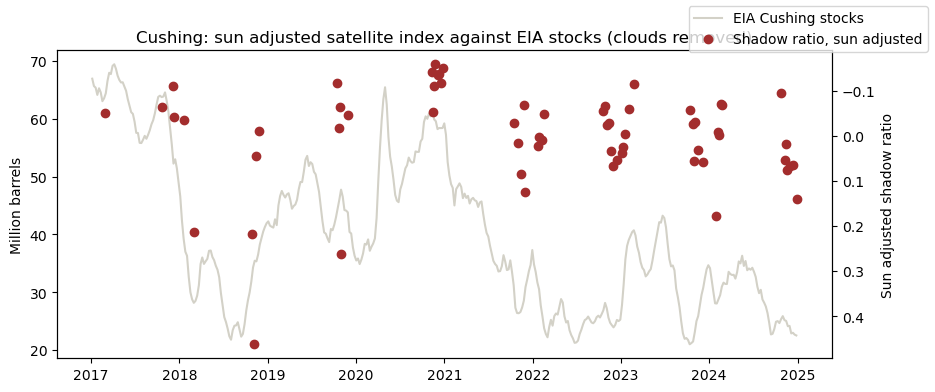

In [22]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "Bocconi student project (Finance with Big Data), contact: giuliano"}
index = pd.read_csv(os.path.join("data", "out", "shadow_index.csv"), index_col="date")
print(index)

EIA_CUSHING = "https://www.eia.gov/dnav/pet/hist_xls/W_EPC0_SAX_YCUOK_MBBLw.xls"  # weekly Cushing stocks
path = os.path.join("data", "raw", "eia_cushing_w.xls")
if not os.path.exists(path):
    reply = requests.get(EIA_CUSHING, headers={"User-Agent": HEADERS["User-Agent"]}, timeout=120)
    with open(path, "wb") as file:
        file.write(reply.content)

table = pd.read_excel(path, sheet_name="Data 1", skiprows=2)
cushing = table.set_index(table.columns[0]).iloc[:, 0].astype(float) / 1000  # million barrels

index.index = pd.to_datetime(index.index)
index["stocks"] = cushing.reindex(index.index, method="nearest").values  # closest weekly report

print(index[["sun_elevation", "ratio", "stocks"]].round(2))
clean = index[index["ratio"] < 0.7]  # ratio near 1 would mean all tanks empty: clouds
print(f"Correlation without cloud images: {clean['ratio'].corr(clean['stocks']):.2f}")

sun_fit = np.polyfit(clean["sun_elevation"], clean["ratio"], 1)          # straight line: ratio on sun
adjusted = clean["ratio"] - np.polyval(sun_fit, clean["sun_elevation"])  # what the sun doesn't explain

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cushing["2017":"2024"], color="#D3D1C7", label="EIA Cushing stocks")
ax.set_ylabel("Million barrels")

ax2 = ax.twinx()
ax2.plot(clean.index, adjusted, "o", color="#A32D2D", label="Shadow ratio, sun adjusted")
ax2.set_ylabel("Sun adjusted shadow ratio")
ax2.invert_yaxis()  # flipped: more shadow should line up with fewer barrels

ax.set_title("Cushing: sun adjusted satellite index against EIA stocks (clouds removed)")
fig.legend(loc="upper right")
plt.show()

In [23]:
import statsmodels.formula.api as smf

clean = index[index["ratio"] < 0.7]  # a ratio near 1 would mean all tanks empty: clouds
model = smf.ols("ratio ~ stocks + sun_elevation", data=clean).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3})  # robust to nearby dates being related
print(model.summary().tables[1])

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.5249      0.099      5.289      0.000       0.330       0.719
stocks           -0.0035      0.001     -4.642      0.000      -0.005      -0.002
sun_elevation    -0.0051      0.003     -1.591      0.112      -0.011       0.001


## Improved index (chosen after seeing results)

In `Satellite_experiments.ipynb` we tested one change at a time. We adopt the three changes that help for a
reason we can explain without the correlation:

* **Black pixels only near the tanks (experiment 1b).** We skip an image only if a black pixel lies within
  40 m of a roof. On five dates the tile edge cuts the window but misses every tank, so these dates come back.
* **Newest processing version (experiment 8).** Many days have two versions of the same tile. The baseline
  takes the older one, because it comes first in the list. We keep the newest, so all years come from
  similar processing.
* **Each image lined up with the reference (experiment 9).** Sentinel 2 places images a few metres off, and
  differently on each date. Half a pixel moves the ratio a lot. We measure each image's shift against the
  2018-01-20 image and move the circles with it. No EIA data enter this step.

**Clouds.** We flag a cloud (ratio ≥ 0.7) with the **unshifted** circles, exactly as in the baseline. Lining
up a cloudy image can move its circles far and hide the cloud.

We chose these changes after seeing the results, so the improved index is not an out-of-sample test. The
baseline above uses rules we fixed in advance, and we show both.

In [24]:
from skimage.registration import phase_cross_correlation

gray_ref = load_chip(reference).mean(axis=2) / 255

# Pixels within 4 pixels (40 m) of a roof: longer than the longest winter shadow (28 m)
rr, cc = np.indices(gray_ref.shape)
near_tanks = np.zeros(gray_ref.shape, dtype=bool)
for (row, col), r in zip(centres, radii):
    near_tanks |= np.hypot(rr + 0.5 - row, cc + 0.5 - col) <= r + 4

# The box around all tanks, plus 20 pixels: the part of each image we line up
top_row, left_col = (centres.min(axis=0) - 20).astype(int)
bottom_row, right_col = (centres.max(axis=0) + 20).astype(int)
FARMS = (slice(top_row, bottom_row), slice(left_col, right_col))


def newest_versions(images):
    """For each day and tile, keep only the image with the newest processing version."""
    newest = {}
    for image in images:
        key = (image["properties"]["datetime"][:10], image["properties"]["mgrs:grid_square"])
        version = float(image["properties"]["s2:processing_baseline"])
        if key not in newest or version > float(newest[key]["properties"]["s2:processing_baseline"]):
            newest[key] = image
    keep = {image["id"] for image in newest.values()}
    return [image for image in images if image["id"] in keep]


def image_shift(gray_k):
    """Shift (rows, columns) of an image against the reference image, to 0.1 pixel."""
    shift, _, _ = phase_cross_correlation(gray_ref[FARMS], gray_k[FARMS], upsample_factor=10)
    return -shift  # the function returns the shift that undoes the movement, so we flip it


def shadow_ratio(gray_k, image, shift=(0, 0), height=TANK_HEIGHT):
    """Dark roof pixels over dark ground shadow pixels, with the circles moved by `shift` pixels."""
    elevation = image["properties"]["view:sun_elevation"]
    azimuth = image["properties"]["view:sun_azimuth"]
    L_px = height / np.tan(np.radians(elevation)) / 10
    direction = np.radians(azimuth + 180)
    roof, ground, _ = shadow_counts(gray_k, centres + np.asarray(shift), radii,
                                    L_px, -np.cos(direction), np.sin(direction))
    return roof / ground

In [25]:
def improved_index(height=TANK_HEIGHT):
    """Shadow index with changes 1b, 8 and 9. The cloud flag uses the unshifted circles."""
    rows = []
    for image in newest_versions(winter):
        date = image["properties"]["datetime"][:10]
        if date in [row["date"] for row in rows]:
            continue  # this day is already measured
        chip_k = load_chip(image)
        if (chip_k.sum(axis=2) == 0)[near_tanks].any():
            continue  # the tile edge cuts a tank or its shadow
        gray_k = chip_k.mean(axis=2) / 255
        shift = image_shift(gray_k)
        if np.abs(shift).max() > 2:
            shift = np.zeros(2)  # failed match: keep the circles where they are
        rows.append({"date": date, "sun_elevation": image["properties"]["view:sun_elevation"],
                     "cloud_ratio": shadow_ratio(gray_k, image, height=height),
                     "ratio": shadow_ratio(gray_k, image, shift, height),
                     "shift_m": 10 * np.hypot(*shift)})
    improved = pd.DataFrame(rows).set_index("date")
    improved.index = pd.to_datetime(improved.index)
    improved["stocks"] = cushing.reindex(improved.index, method="nearest").values
    return improved


improved = improved_index()
improved.to_csv("data/out/shadow_index_improved.csv")
print(f"{len(improved)} dates. We move the circles by {improved['shift_m'].median():.1f} m on the median "
      f"date, {improved['shift_m'].max():.0f} m at most.")

69 dates. We move the circles by 3.2 m on the median date, 14 m at most.


**Tank height.** We keep 15 m: typical Cushing tanks are 48 ft (14.6 m) high (Oil & Gas Journal; Industrial
Info). We show 18 m as a realistic robustness check, and 12 m as a stress test below the reported Cushing tank
height.

In [26]:
def test(data, cloud_column="ratio"):
    """Dates, correlation without clouds, and the HAC regression of the ratio on stocks."""
    clean = data[data[cloud_column] < 0.7]  # a ratio near 1 would mean all tanks empty: clouds
    model = smf.ols("ratio ~ stocks + sun_elevation", data=clean).fit(
        cov_type="HAC", cov_kwds={"maxlags": 3})
    return {"dates": len(data), "dates without clouds": len(clean),
            "correlation": clean["ratio"].corr(clean["stocks"]),
            "stocks coef": model.params["stocks"], "HAC z": model.tvalues["stocks"]}


comparison = pd.DataFrame({
    "Baseline, 15 m (rules fixed in advance)": test(index),
    "Improved, 15 m (chosen after seeing results)": test(improved, "cloud_ratio"),
    "Improved, 18 m (robustness)": test(improved_index(18), "cloud_ratio"),
    "Improved, 12 m (stress test, below the reported Cushing tank height)": test(improved_index(12),
                                                                                 "cloud_ratio"),
}).T
comparison = comparison.astype({"dates": int, "dates without clouds": int})
comparison.round({"correlation": 2, "stocks coef": 4, "HAC z": 1})

,dates,dates without clouds,correlation,stocks coef,HAC z
"Baseline, 15 m (rules fixed in advance)",64,62,-0.40,-0.0035,-4.6
"Improved, 15 m (chosen after seeing results)",69,67,-0.66,-0.0037,-6.1
"Improved, 18 m (robustness)",69,68,-0.64,-0.0033,-6.0
"Improved, 12 m (stress test, below the reported Cushing tank height)",69,65,-0.67,-0.0043,-6.0


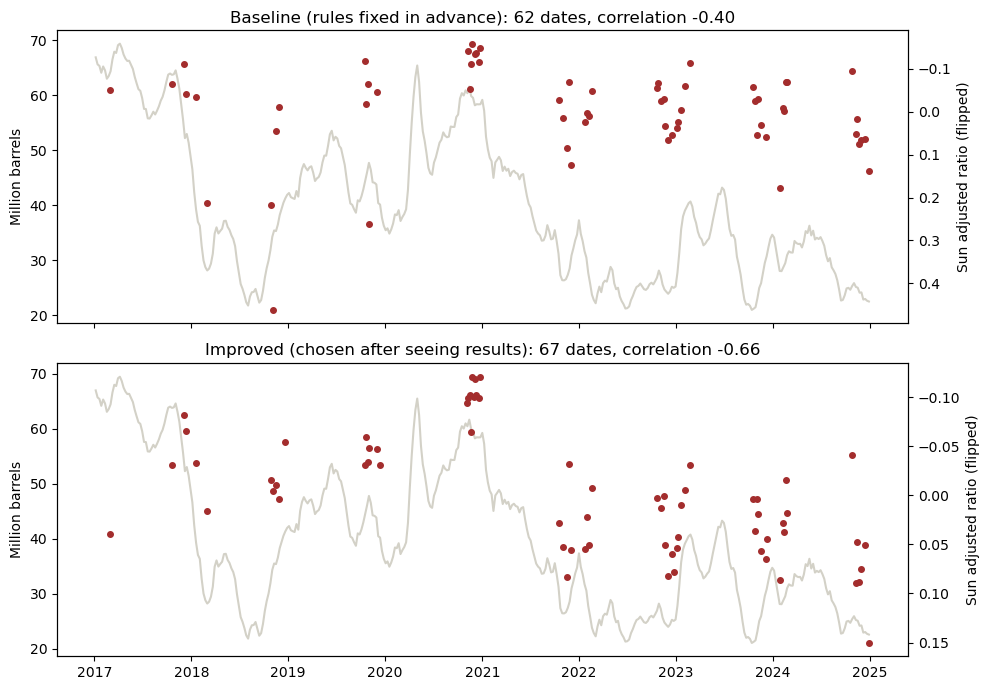

In [27]:
versions = {"Baseline (rules fixed in advance)": index[index["ratio"] < 0.7],
            "Improved (chosen after seeing results)": improved[improved["cloud_ratio"] < 0.7]}

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (name, data) in zip(axes, versions.items()):
    sun_fit = np.polyfit(data["sun_elevation"], data["ratio"], 1)
    adjusted = data["ratio"] - np.polyval(sun_fit, data["sun_elevation"])
    ax.plot(cushing["2017":"2024"], color="#D3D1C7")
    ax.set_ylabel("Million barrels")
    ax2 = ax.twinx()
    ax2.plot(data.index, adjusted, "o", color="#A32D2D", markersize=4)
    ax2.set_ylabel("Sun adjusted ratio (flipped)")
    ax2.invert_yaxis()  # flipped: more shadow should line up with fewer barrels
    ax.set_title(f"{name}: {len(data)} dates, correlation {data['ratio'].corr(data['stocks']):.2f}")
plt.tight_layout()
plt.show()

**Comments**
* **Stronger link to the stocks.** The improved index keeps 67 dates without clouds (baseline 62). Its correlation with EIA Cushing stocks rises from −0.40 to −0.66, and the HAC z from −4.6 to −6.1. The slope barely changes (−0.0037 against −0.0035), so the gain comes from less noise, not from a different relation.
* **Tank height no longer matters much.** With 18 m the correlation is −0.64, with 12 m −0.67. In the baseline the two heights gave −0.39 and −0.52 (`Satellite_experiments.ipynb`).
* **Small shifts, big effect.** We move the circles by 3.2 m on the median date and by 14 m at most, less than one and a half pixels.
* **Levels, not weekly changes.** The index follows the level of Cushing stocks. Between dates at most 30 days apart the link is weak (z −1.8, `Satellite_experiments.ipynb`, experiment 10), so it gives us no edge on the weekly EIA number.